In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import AutoMinorLocator
from pathlib import Path

In [2]:
# --- User settings: adjust these for each measurement ---
INPUT_FILE   = Path("260612_400_02.txt")   # path to the XRD data file (two columns: 2θ, intensity)
SAMPLE_LABEL = "Sample 260612_400_02.txt"      # text shown in the plot legend
OUTPUT_STEM  = "xrd_ts5_N2O_400kGytest"         # base name of the saved PDF (without file extension)

## 1. Load data

In [3]:
# Read the data file: a comma-separated table with no header line.
# Column 1 is the diffraction angle 2θ (in degrees), column 2 is the measured intensity.
df = pd.read_csv(
    INPUT_FILE,
    sep=",",
    header=None,
    names=["two_theta", "intensity"],
    skip_blank_lines=True,
)

# pull the two columns out as plain NumPy arrays for the calculations below
two_theta = df["two_theta"].to_numpy()
intensity = df["intensity"].to_numpy()

print(f"Loaded {len(df)} points, 2θ range: {two_theta.min():.2f}° – {two_theta.max():.2f}°")
df.head()

Loaded 1601 points, 2θ range: 20.00° – 100.00°


,two_theta,intensity
0,20.00,86.450
1,20.05,86.025
2,20.10,89.950
3,20.15,88.875
4,20.20,89.550


## 2. Matplotlib style

In [4]:
# Global plot style: serif fonts, inward-pointing ticks and consistent sizes,
# so every figure comes out with the same publication-ready look.
plt.rcParams.update({
    "font.family":       "serif",
    "font.serif":        ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":         11,
    "axes.labelsize":    12,
    "axes.titlesize":    12,
    "xtick.labelsize":   10,
    "ytick.labelsize":   10,
    "legend.fontsize":   10,
    "axes.linewidth":    0.9,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "xtick.major.size":  5,
    "ytick.major.size":  5,
    "xtick.minor.size":  2.5,
    "ytick.minor.size":  2.5,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.minor.width": 0.7,
    "ytick.minor.width": 0.7,
    "mathtext.fontset":  "dejavuserif",
})

## 3. Plot the diffractogram

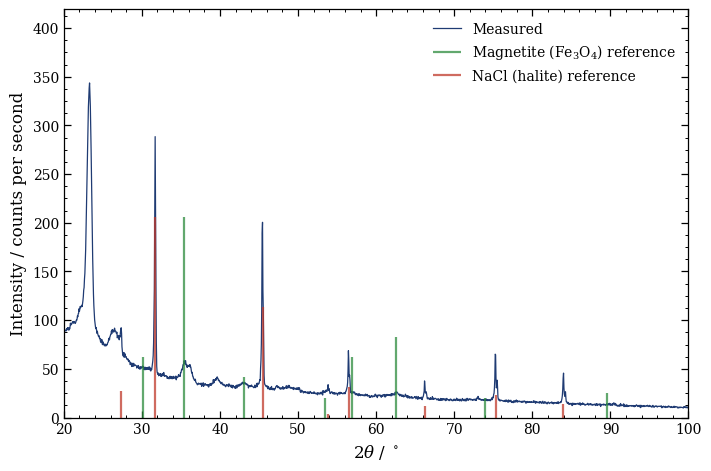

In [ ]:
# --- Plot range ---
# Set PLOT_RANGE to None to show the full measured 2θ range, or to a
# (xmin, xmax) tuple in degrees to zoom into a region, e.g. (20, 70).
PLOT_RANGE = (20, 100)
if PLOT_RANGE is None:
    tt_plot, int_plot = two_theta, intensity
else:
    # keep only the data points whose 2θ lies inside the chosen window
    m = (two_theta >= PLOT_RANGE[0]) & (two_theta <= PLOT_RANGE[1])
    tt_plot, int_plot = two_theta[m], intensity[m]

# --- Reference phase toggles ---
# Not every sample contains every phase, so turn each reference on or off here.
# Set a flag to False to hide that phase's reference sticks for the current
# sample without deleting anything below.
SHOW_MAGNETITE = True
SHOW_NACL      = True
SHOW_HEMATITE  = False

# --- Magnetite reference reflections (Fe3O4, Cu Kα, ICDD card 19-0629) ---
# These are the known peak positions of magnetite, used to check whether the
# measured pattern matches it. The positions are derived from the tabulated
# d-spacings (Cornell & Schwertmann, 2003) via Bragg's law
# (2θ = 2·arcsin(λ / 2d)). The intensities are relative values, normalised so
# the strongest reflection, (311), equals 100.
magnetite_peaks       = np.array([30.10, 35.42, 43.05, 53.39, 56.94,
                                  62.52, 73.95, 89.62])
magnetite_intensities = np.array([  30,   100,    20,    10,    30,
                                     40,    10,    12])

# --- NaCl (halite) reference reflections (NaCl, Cu Kα, ICDD card 05-0628) ---
# These are the known peak positions of halite (rock salt), used to check
# whether the measured pattern matches it. The positions are derived from the
# lattice parameter a = 5.6402 Å (Wyckoff, 1963) via Bragg's law
# (2θ = 2·arcsin(λ / 2d)). The intensities are relative values, normalised so
# the strongest reflection, (200), equals 100.
nacl_peaks       = np.array([27.37, 31.70, 45.45, 53.87, 56.47,
                             66.23, 75.29, 83.99])
nacl_intensities = np.array([  13,   100,    55,    2,    15,
                                6,    11,     7])

# --- Hematite reference reflections (α-Fe2O3, Cu Kα, ICDD card 34-0664) ---
# These are the known peak positions of hematite, used to check whether the
# measured pattern matches it. The positions are derived from the tabulated
# d-spacings (Cornell & Schwertmann, 2003, Tab. 7.10) via Bragg's law
# (2θ = 2·arcsin(λ / 2d)). The intensities are relative values, normalised so
# the strongest reflection, (104), equals 100.
# Note: the book tabulates d(110) = 0.2591 nm, which places (110) at 34.59°; this
# is almost certainly a typo for 0.2519 nm (the accepted value, → 35.61°). Swap
hematite_peaks       = np.array([24.14, 33.15, 35.61, 40.86, 49.48,  # 34.59 = (110); see NB above (→ 35.61)
                                 54.09, 57.59, 62.45, 63.99, 71.94,
                                 72.26, 75.43, 80.71, 82.94, 84.92,
                                 88.54, 93.72])
hematite_intensities = np.array([  30,   100,    70,    20,    40,
                                   45,    10,    30,    30,    10,
                                    6,     8,     5,     5,     7,
                                    7,     7])

# --- Plot ---
fig, ax = plt.subplots(figsize=(7.0, 4.6), constrained_layout=True)

# the measured diffraction pattern
ax.plot(tt_plot, int_plot, color="#1f3b73", linewidth=0.9, label="Measured")

# Draw the reference reflections as vertical sticks. Their heights use the
# relative intensities above, scaled down to 60 % of the measured maximum so
# the tallest stick ((311), intensity 100) does not overpower the actual data.
y_max = int_plot.max() * 1.22
stick_scale = 0.6 * int_plot.max() / 100.0

if SHOW_MAGNETITE:
    # only show the reference peaks that fall inside the plotted 2θ range
    in_range = (magnetite_peaks >= tt_plot.min()) & (magnetite_peaks <= tt_plot.max())
    ref_pos = magnetite_peaks[in_range]
    ref_int = magnetite_intensities[in_range]
    ax.vlines(ref_pos, ymin=0, ymax=ref_int * stick_scale,
              color="#2e8b3d", linewidth=1.6, alpha=0.75,
              label=r"Magnetite (Fe$_3$O$_4$) reference")

if SHOW_NACL:
    # only show the reference peaks that fall inside the plotted 2θ range
    in_range = (nacl_peaks >= tt_plot.min()) & (nacl_peaks <= tt_plot.max())
    ref_pos = nacl_peaks[in_range]
    ref_int = nacl_intensities[in_range]
    ax.vlines(ref_pos, ymin=0, ymax=ref_int * stick_scale,
              color="#c0392b", linewidth=1.6, alpha=0.75,
              label="NaCl (halite) reference")

if SHOW_HEMATITE:
    # only show the reference peaks that fall inside the plotted 2θ range
    in_range = (hematite_peaks >= tt_plot.min()) & (hematite_peaks <= tt_plot.max())
    ref_pos = hematite_peaks[in_range]
    ref_int = hematite_intensities[in_range]
    ax.vlines(ref_pos, ymin=0, ymax=ref_int * stick_scale,
              color="#e67e22", linewidth=1.6, alpha=0.75,
              label=r"Hematite ($\alpha$-Fe$_2$O$_3$) reference")

ax.set_xlabel(r"$2\theta$ / $^\circ$")
ax.set_ylabel("Intensity / counts per second")
ax.set_xlim(tt_plot.min(), tt_plot.max())
ax.set_ylim(0, y_max)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.legend(frameon=False, loc="upper right")

# save the figure as a PDF and display it
fig.savefig(f"{OUTPUT_STEM}.pdf")
plt.show()

Pseudo-Voigt peak positions for the lattice-parameter analysis
(311)  2theta0 =  35.503 +- 0.020 deg   FWHM = 0.836 +- 0.098 deg   eta = 0.90
       a_hkl = 8.3795 +- 0.0047 A (fit error only)
(400)  2theta0 =  43.032 +- 0.036 deg   FWHM = 0.924 +- 0.113 deg   eta = 0.19
       a_hkl = 8.4012 +- 0.0067 A (fit error only)
(440)  2theta0 =  62.618 +- 0.039 deg   FWHM = 0.891 +- 0.160 deg   eta = 1.00
       a_hkl = 8.3854 +- 0.0047 A (fit error only)
Copy into indexed_peaks below (after checking the warnings):
indexed_peaks = [
    (35.503, 3, 1, 1),   # WARNING above - check before using
    (43.032, 4, 0, 0),
    (62.618, 4, 4, 0),
]


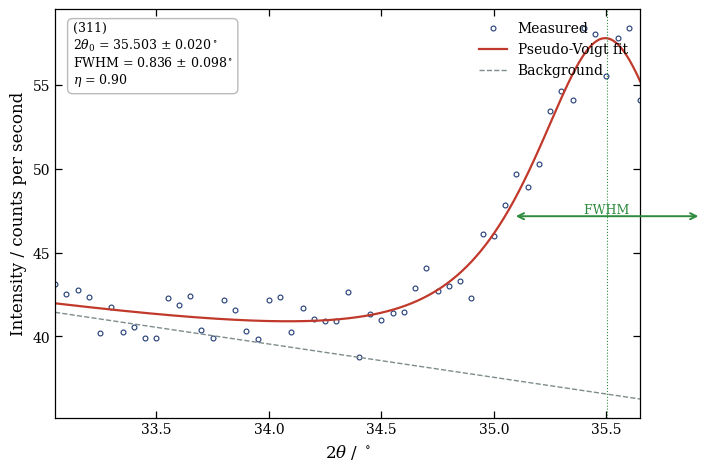

In [6]:
# =============================================================================
# precise magnetite peak positions from pseudo-Voigt fits
# =============================================================================
# The peak positions entering the lattice-parameter analysis are determined by
# fitting a pseudo-Voigt profile on a linear background (the same profile and
# fitting procedure as in the Scherrer cell below) inside a small 2-theta
# window around each reflection. The fit uses the whole peak profile, so it is
# not tied to the 0.05 deg measurement grid, it is robust against noise spikes
# sitting on top of broad reflections, and it returns an uncertainty for the
# position.
#
# Workflow:
#   1. Inspect the diffractogram plot above and decide which reflections are
#      visible and can be assigned to magnetite.
#   2. For each of them, add one entry (h, k, l, 2theta_min, 2theta_max) to
#      FIT_PEAKS below. Choose each window wide enough to contain the whole
#      peak plus some background on both sides, but narrow enough that NO
#      foreign reflection (NaCl, hematite, PEG, ...) lies inside. If a foreign
#      reflection overlaps the magnetite peak itself, do not fit it - exclude
#      the reflection instead.
#   3. Run the cell, read the warnings, inspect fits with PLOT_PEAK, and copy
#      the accepted positions into indexed_peaks in the lattice-parameter cell
#      below.
#
# Suggested default windows (adjust after checking them against the plot):
#   (2,2,0, 28.6, 31.2)   NaCl (200) at 31.70 must stay outside
#   (3,1,1, 33.0, 38.0)   hematite (110) at 35.61 lies inside the peak,
#                         gel samples show a second peak at ~36.0
#   (4,0,0, 41.6, 44.6)
#   (5,1,1, 55.6, 58.4)   NaCl (222) at 56.47 and hematite (018) at 57.59
#   (4,4,0, 60.4, 64.6)   hematite (214) at 62.45 coincides with (440)
#   (5,3,3, 72.6, 75.0)   NaCl (331) at 73.07 and NaCl (420) at 75.29
#   (7,3,1, 88.3, 91.3)   NaCl (511)+(333) at 90.42
# The (422) reflection is not listed: it overlaps with hematite (116) at 54.09
# and NaCl (311) at 53.87 and is therefore not reliably fittable.

from scipy.optimize import curve_fit

# --- User settings ---
LAMBDA_PV = 1.5406   # X-ray wavelength in Angstrom (Cu K-alpha)
A_LIT     = 8.396    # literature lattice parameter of magnetite in Angstrom,
                     # used only for the advisory assignment check below

FIT_PEAKS = [
    (3, 1, 1, 33.0, 35.7),
    (4, 0, 0, 41.6, 44.6),
    (4, 4, 0, 60.4, 64.6),
]

# Set PLOT_PEAK to the Miller indices of ONE fitted reflection, e.g. (4, 4, 0),
# to display that fit for visual inspection (measured points, fitted profile,
# background and FWHM, in the same style as the (311) Scherrer plot below).
# Set it to None to show no plot. The plot is for inspection only and is not
# saved to disk.
PLOT_PEAK = (3, 1, 1)    #None

def pseudo_voigt(x, A, x0, fwhm, eta, m, c):
    # same profile as in the Scherrer cell below: a Gaussian/Lorentzian mixture
    # of common centre and width on a straight-line background
    sigma = fwhm / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    gauss = np.exp(-((x - x0) ** 2) / (2.0 * sigma ** 2))
    gamma = fwhm / 2.0
    lor   = gamma ** 2 / ((x - x0) ** 2 + gamma ** 2)
    return A * (eta * lor + (1.0 - eta) * gauss) + m * x + c

print("Pseudo-Voigt peak positions for the lattice-parameter analysis")
print("=" * 74)

paste_lines = []
fit_results = {}   # successful fits, keyed by (h, k, l), for the optional plot
for h, k, l, lo, hi in FIT_PEAKS:
    name = f"({h}{k}{l})"

    mask = (two_theta > lo) & (two_theta < hi)
    if mask.sum() < 15:
        print(f"{name}  window {lo}-{hi} deg contains too few data points -> skipped")
        continue
    x_fit, y_fit = two_theta[mask], intensity[mask]

    # starting guesses and bounds, identical to the Scherrer fit below
    p0 = [y_fit.max() - np.median(y_fit),
          x_fit[np.argmax(y_fit)],
          1.0,
          0.5,
          0.0,
          np.median(y_fit)]
    bounds = (
        [0,      x_fit.min(), 0.05, 0.0, -np.inf, -np.inf],
        [np.inf, x_fit.max(), 5.0,  1.0,  np.inf,  np.inf],
    )
    try:
        popt, pcov = curve_fit(pseudo_voigt, x_fit, y_fit, p0=p0, bounds=bounds,
                               maxfev=20000)
    except Exception as exc:
        print(f"{name}  fit did not converge -> excluded ({exc})")
        continue
    A_amp, x0, fwhm, eta, m_bg, c_bg = popt
    perr = np.sqrt(np.diag(pcov))

    # noise level of the residuals, used to judge whether the peak is real
    noise = np.std(y_fit - pseudo_voigt(x_fit, *popt))

    # per-reflection lattice parameter and its fit-only uncertainty, printed
    # for information; the uncertainty of the mean lattice parameter is still
    # taken from the scatter between the reflections (next cell)
    theta = np.deg2rad(x0 / 2.0)
    d_hkl = LAMBDA_PV / (2.0 * np.sin(theta))
    a_hkl = d_hkl * np.sqrt(h * h + k * k + l * l)
    a_err = a_hkl / np.tan(theta) * np.deg2rad(perr[1]) / 2.0

    # advisory quality checks; a warning does not exclude the peak, it asks
    # you to look at the diffractogram before using the value
    warn = []
    if perr[1] > 0.15:
        warn.append(f"position uncertainty {perr[1]:.3f} deg > 0.15 deg")
    if abs(a_hkl - A_LIT) > 0.05:
        warn.append(f"a_hkl deviates {abs(a_hkl - A_LIT):.3f} A from the magnetite "
                    f"literature value -> check assignment (foreign reflection or "
                    f"strongly oxidized phase?)")
    if fwhm < 0.3:
        warn.append("FWHM < 0.3 deg -> unusually sharp for the nanoparticle "
                    "samples, possibly a salt reflection or a noise spike")
    if perr[2] > fwhm:
        warn.append("FWHM poorly constrained (uncertainty exceeds the value)")
    if (x0 - lo) < 0.1 * (hi - lo) or (hi - x0) < 0.1 * (hi - lo):
        warn.append("fitted position close to window edge -> widen/shift window")
    if fwhm > 4.9:
        warn.append("FWHM at upper fit bound -> peak too broad for this window")
    if A_amp < 3.0 * noise:
        warn.append(f"amplitude {A_amp:.1f} < 3x residual noise ({noise:.1f}) "
                    f"-> peak not significant")

    print(f"{name}  2theta0 = {x0:7.3f} +- {perr[1]:.3f} deg   "
          f"FWHM = {fwhm:.3f} +- {perr[2]:.3f} deg   eta = {eta:.2f}")
    print(f"       a_hkl = {a_hkl:.4f} +- {a_err:.4f} A (fit error only)")
    for w in warn:
        print(f"       WARNING: {w}")

    if warn:
        paste_lines.append(f"    ({x0:.3f}, {h}, {k}, {l}),   # WARNING above - check before using")
    else:
        paste_lines.append(f"    ({x0:.3f}, {h}, {k}, {l}),")

    fit_results[(h, k, l)] = {"x_fit": x_fit, "y_fit": y_fit,
                              "popt": popt, "perr": perr}

print("=" * 74)
print("Copy into indexed_peaks below (after checking the warnings):")
print("indexed_peaks = [")
for line in paste_lines:
    print(line)
print("]")


# --- Optional visual inspection of one fit (set PLOT_PEAK above) ------------
if PLOT_PEAK is not None:
    if PLOT_PEAK not in fit_results:
        print(f"\nPLOT_PEAK {PLOT_PEAK}: no successful fit stored - "
              f"check FIT_PEAKS and the messages above.")
    else:
        res = fit_results[PLOT_PEAK]
        A_p, x0_p, fwhm_p, eta_p, m_p, c_p = res["popt"]
        x_p, y_p, perr_p = res["x_fit"], res["y_fit"], res["perr"]

        # smooth curve of the fitted profile and its linear background
        x_model = np.linspace(x_p.min(), x_p.max(), 500)
        y_model = pseudo_voigt(x_model, *res["popt"])
        y_background = m_p * x_model + c_p

        # half-maximum level above the local background, to draw the FWHM
        bg_at_centre = m_p * x0_p + c_p
        y_halfmax    = bg_at_centre + A_p / 2.0

        fig, ax = plt.subplots(figsize=(7.0, 4.6), constrained_layout=True)
        ax.plot(x_p, y_p, marker="o", linestyle="none", markersize=3.5,
                markerfacecolor="none", markeredgecolor="#1f3b73",
                markeredgewidth=0.8, label="Measured")
        ax.plot(x_model, y_model, color="#c0392b", linewidth=1.6,
                label="Pseudo-Voigt fit")
        ax.plot(x_model, y_background, color="#7f8c8d", linewidth=1.0,
                linestyle="--", label="Background")
        ax.annotate("", xy=(x0_p - fwhm_p / 2.0, y_halfmax),
                    xytext=(x0_p + fwhm_p / 2.0, y_halfmax),
                    arrowprops=dict(arrowstyle="<->", color="#2e8b3d",
                                    linewidth=1.4))
        ax.text(x0_p, y_halfmax, " FWHM ", color="#2e8b3d",
                va="bottom", ha="center", fontsize=9)
        ax.axvline(x0_p, color="#2e8b3d", linewidth=0.8, linestyle=":")

        hh, kk, ll = PLOT_PEAK
        info = (f"({hh}{kk}{ll})\n"
                f"2$\\theta_0$ = {x0_p:.3f} $\\pm$ {perr_p[1]:.3f}$^\\circ$\n"
                f"FWHM = {fwhm_p:.3f} $\\pm$ {perr_p[2]:.3f}$^\\circ$\n"
                f"$\\eta$ = {eta_p:.2f}")
        ax.text(0.03, 0.97, info, transform=ax.transAxes, va="top", ha="left",
                fontsize=9, bbox=dict(boxstyle="round,pad=0.4",
                                      facecolor="white", edgecolor="0.7",
                                      alpha=0.9))
        ax.set_xlabel(r"$2\theta$ / $^\circ$")
        ax.set_ylabel("Intensity / counts per second")
        ax.set_xlim(x_p.min(), x_p.max())
        ax.legend(frameon=False, loc="upper right")
        plt.show()

## 5. Lattice parameter and Scherrer crystallite size

In [7]:
from scipy.optimize import curve_fit

# --- User settings ---
LAMBDA        = 1.5406   # X-ray wavelength in Å (Cu Kα)
K_SHAPE       = 0.9      # Scherrer shape factor; ≈0.9 for roughly spherical crystallites

# --- Manual peak indexing ---
# List the peaks you identified, each with the Miller indices (h, k, l) you
# assigned to it. Format per entry: (2θ in degrees, h, k, l). Ready-made lists
# for the different datasets are collected in the markdown cell below.
indexed_peaks = [
    (35.414, 3, 1, 1),
    (43.153, 4, 0, 0),
    (62.558, 4, 4, 0),   # WARNING above - check before using
]

# --- 1. Lattice parameter from each indexed reflection ---
# For a cubic crystal, every reflection gives the lattice parameter a from its
# d-spacing and its indices: a = d · √(h²+k²+l²). Doing this for several peaks
# and averaging gives a more reliable value than a single peak would.
print("Lattice parameter calculation")
print("-" * 56)
print(f"{'(hkl)':>8}  {'2θ (°)':>8}  {'d (Å)':>8}  {'a (Å)':>8}")
print("-" * 56)

a_values = []
for two_t, h, k, l in indexed_peaks:
    theta = np.deg2rad(two_t / 2.0)          # Bragg angle θ (half of 2θ), in radians
    d     = LAMBDA / (2.0 * np.sin(theta))   # d-spacing from Bragg's law
    N     = h*h + k*k + l*l
    a     = d * np.sqrt(N)                    # lattice parameter for a cubic cell
    a_values.append(a)
    print(f"  ({h}{k}{l})  {two_t:8.2f}  {d:8.4f}  {a:8.4f}")

a_values = np.array(a_values)
a_mean   = a_values.mean()
a_std    = a_values.std(ddof=1)              # spread between the individual values
print("-" * 56)
print(f"Mean lattice parameter: a = {a_mean:.3f} ± {a_std:.3f} Å  "
      f"(N = {len(a_values)})")
print(f"Literature (Fe3O4):  a = 8.396 Å")

# --- 2. Crystallite size from the (311) peak (Scherrer equation) ---
# The Scherrer equation estimates the crystallite size from how broad a peak
# is: D = K·λ / (β·cosθ), where β is the peak width (FWHM) in radians and θ is
# the Bragg angle. To obtain β we fit a pseudo-Voigt profile (a mixture of a Gaussian and a
# Lorentzian) on a straight-line background to the (311) peak.

def pseudo_voigt(x, A, x0, fwhm, eta, m, c):
    sigma = fwhm / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    gauss = np.exp(-((x - x0) ** 2) / (2.0 * sigma ** 2))
    gamma = fwhm / 2.0
    lor   = gamma ** 2 / ((x - x0) ** 2 + gamma ** 2)
    return A * (eta * lor + (1.0 - eta) * gauss) + m * x + c

# cut out a narrow 2θ window around the (311) peak to fit
mask  = (two_theta > 33.0) & (two_theta < 38.0)
x_fit = two_theta[mask]
y_fit = intensity[mask]

# starting guesses for the six fit parameters
p0 = [y_fit.max() - np.median(y_fit),    # amplitude (peak height above background)
      x_fit[np.argmax(y_fit)],           # centre position (2θ)
      1.0,                                # peak width FWHM, first guess (deg)
      0.5,                                # Gaussian/Lorentzian mixing (0 to 1)
      0.0,                                # background slope
      np.median(y_fit)]                   # background offset

# allowed range for each parameter, given as (lower bounds, upper bounds)
bounds = (
    [0,         x_fit.min(), 0.05, 0.0, -np.inf, -np.inf],
    [np.inf,    x_fit.max(), 5.0,  1.0,  np.inf,  np.inf],
)
popt, pcov = curve_fit(pseudo_voigt, x_fit, y_fit, p0=p0, bounds=bounds)
_, x0_fit, fwhm_obs_deg, eta_fit, _, _ = popt   # we only need centre, width and mixing
perr = np.sqrt(np.diag(pcov))                   # standard error of each fitted parameter

# plug the fitted width and position into the Scherrer equation
beta_obs_rad = np.deg2rad(fwhm_obs_deg)         # peak width β in radians
theta_311    = np.deg2rad(x0_fit / 2.0)         # Bragg angle θ in radians
D_A  = K_SHAPE * LAMBDA / (beta_obs_rad * np.cos(theta_311))   # crystallite size in Å
D_nm = D_A / 10.0                                              # same size in nm

# propagate the fit uncertainties (peak width and position) into the size error
beta_err_rad  = np.deg2rad(perr[2])
theta_err_rad = np.deg2rad(perr[1]) / 2.0   # the error of θ is half the error of 2θ
rel_err = np.sqrt(
    (beta_err_rad / beta_obs_rad) ** 2
    + (np.tan(theta_311) * theta_err_rad) ** 2
)
D_err_nm = rel_err * D_nm

print()
print("Scherrer analysis on (311)")
print("-" * 56)
print(f"  Fitted position : 2θ = {x0_fit:.3f} ± {perr[1]:.3f}°")
print(f"  Observed FWHM   : β  = {fwhm_obs_deg:.3f} ± {perr[2]:.3f}°")
print(f"  Profile mixing  : η  = {eta_fit:.2f}   (0 = Gauss, 1 = Lorentz)")
print(f"  Crystallite size: D  = {D_nm:.1f} ± {D_err_nm:.1f} nm")

Lattice parameter calculation
--------------------------------------------------------
   (hkl)    2θ (°)     d (Å)     a (Å)
--------------------------------------------------------
  (311)     35.41    2.5326    8.3998
  (400)     43.15    2.0947    8.3787
  (440)     62.56    1.4836    8.3926
--------------------------------------------------------
Mean lattice parameter: a = 8.390 ± 0.011 Å  (N = 3)
Literature (Fe3O4):  a = 8.396 Å

Scherrer analysis on (311)
--------------------------------------------------------
  Fitted position : 2θ = 35.726 ± 0.016°
  Observed FWHM   : β  = 1.349 ± 0.043°
  Profile mixing  : η  = 0.00   (0 = Gauss, 1 = Lorentz)
  Crystallite size: D  = 6.2 ± 0.2 nm


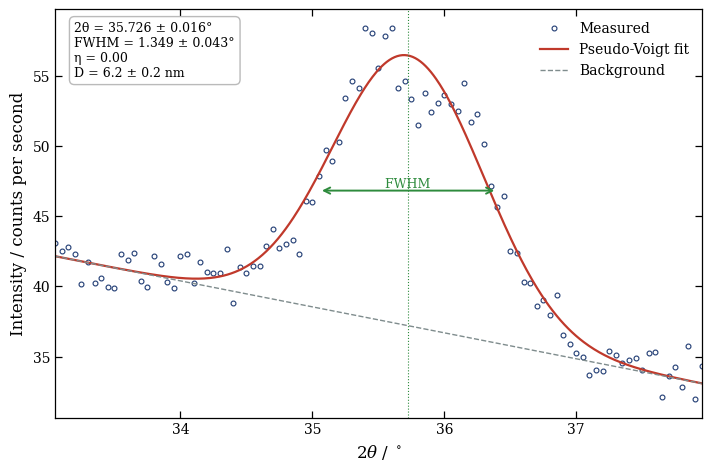

In [8]:
# --- Visualise the (311) pseudo-Voigt fit used for the FWHM / Scherrer step ---
# This cell only plots the fit produced in the cell above; run that cell first.

# unpack the full fit result (popt is still in scope from the fit above)
A_fit, x0_fit, fwhm_fit, eta_fit, m_fit, c_fit = popt

# smooth curve of the fitted profile over the fit window
x_model = np.linspace(x_fit.min(), x_fit.max(), 500)
y_model = pseudo_voigt(x_model, *popt)

# the straight-line background that was fitted underneath the peak
y_background = m_fit * x_model + c_fit

# half-maximum level above the local background, used to draw the FWHM as a
# horizontal segment of exactly the fitted width
bg_at_centre = m_fit * x0_fit + c_fit
y_halfmax    = bg_at_centre + A_fit / 2.0

fig, ax = plt.subplots(figsize=(7.0, 4.6), constrained_layout=True)

# measured points inside the fit window
ax.plot(x_fit, y_fit, marker="o", linestyle="none", markersize=3.5,
        markerfacecolor="none", markeredgecolor="#1f3b73",
        markeredgewidth=0.8, label="Measured")

# the fitted pseudo-Voigt profile and its background
ax.plot(x_model, y_model, color="#c0392b", linewidth=1.6, label="Pseudo-Voigt fit")
ax.plot(x_model, y_background, color="#7f8c8d", linewidth=1.0,
        linestyle="--", label="Background")

# FWHM indicator: a double-headed arrow at half maximum spanning the fitted width
ax.annotate("", xy=(x0_fit - fwhm_fit / 2.0, y_halfmax),
            xytext=(x0_fit + fwhm_fit / 2.0, y_halfmax),
            arrowprops=dict(arrowstyle="<->", color="#2e8b3d", linewidth=1.4))
ax.text(x0_fit, y_halfmax, f" FWHM ",
        color="#2e8b3d", va="bottom", ha="center", fontsize=9) # = {fwhm_fit:.3f}°
ax.axvline(x0_fit, color="#2e8b3d", linewidth=0.8, linestyle=":")

# small results box
info = (f"2θ = {x0_fit:.3f} ± {perr[1]:.3f}°\n"
        f"FWHM = {fwhm_fit:.3f} ± {perr[2]:.3f}°\n"
        f"η = {eta_fit:.2f}\n"
        f"D = {D_nm:.1f} ± {D_err_nm:.1f} nm")
ax.text(0.03, 0.97, info, transform=ax.transAxes, va="top", ha="left",
        fontsize=9, bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                              edgecolor="0.7", alpha=0.9))

ax.set_xlabel(r"$2\theta$ / $^\circ$")
ax.set_ylabel("Intensity / counts per second")
ax.set_xlim(x_fit.min(), x_fit.max())
ax.legend(frameon=False, loc="upper right")
#fig.savefig(f"{OUTPUT_STEM}_fit.pdf")
plt.show()